1. Setup

In [7]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT_DIR = "/content/drive/MyDrive/IE_7615_generative/data"
except ImportError:
    ROOT_DIR = "./IE_7615_generative/data"

!pip -q install transformers pandas pillow requests tqdm

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


2. Config

In [8]:
import io, json, re, random, zipfile
from collections import defaultdict, Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import requests
import pandas as pd
from PIL import Image, ImageOps
from tqdm.auto import tqdm

SEED         = 42        # shared fixed seed
N_TARGET     = 2000      # subset size (1k-5k)
IMG_SIZE     = 512
CAPTION_RULE = "first"   # "first" = lowest annotation ID per image, or "longest"
MIN_WORDS    = 3         # drop captions shorter than this
MAX_TOKENS   = 77        # CLIP limit (incl. start/end tokens)

ROOT = Path(ROOT_DIR)
RAW  = ROOT / "raw"
PROC = ROOT / f"processed_{IMG_SIZE}"
for p in (RAW, PROC):
    p.mkdir(parents=True, exist_ok=True)

3. Download COCO caption annotations

In [9]:
ANN_ZIP_URL = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"
ANN_PATH    = RAW / "captions_val2017.json"

if not ANN_PATH.exists():
    zip_path = RAW / "annotations_trainval2017.zip"
    with requests.get(ANN_ZIP_URL, stream=True, timeout=60) as r:
        r.raise_for_status()
        with open(zip_path, "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    with zipfile.ZipFile(zip_path) as z:
        with z.open("annotations/captions_val2017.json") as src, open(ANN_PATH, "wb") as dst:
            dst.write(src.read())
    zip_path.unlink()

with open(ANN_PATH) as f:
    coco = json.load(f)

images = {im["id"]: im for im in coco["images"]}
caps = defaultdict(list)
for a in sorted(coco["annotations"], key=lambda a: a["id"]):
    caps[a["image_id"]].append(a["caption"])

print(f"Images in val2017: {len(images)} | Images with captions: {len(caps)}")

Images in val2017: 5000 | Images with captions: 5000


4. Caption rule, cleaning, and subset selection

In [10]:
def clean_caption(c):
    c = c.replace("\n", " ")
    c = re.sub(r"\s+", " ", c)      # collapse repeated whitespace
    return c.strip()

def normalize(c):
    # used only for duplicate detection
    return re.sub(r"[^a-z0-9 ]", "", c.lower()).strip()

def pick_caption(captions, rule):
    cleaned = [clean_caption(c) for c in captions]
    cleaned = [c for c in cleaned if c]
    if not cleaned:
        return None
    return cleaned[0] if rule == "first" else max(cleaned, key=len)

rng = random.Random(SEED)
image_ids = sorted(caps.keys())
rng.shuffle(image_ids)

selected, seen, dropped = [], set(), Counter()
for img_id in image_ids:
    cap = pick_caption(caps[img_id], CAPTION_RULE)
    if cap is None:
        dropped["empty"] += 1; continue
    norm = normalize(cap)
    if len(norm.split()) < MIN_WORDS:
        dropped["too_short"] += 1; continue
    if norm in seen:
        dropped["duplicate"] += 1; continue
    seen.add(norm)
    selected.append({"image_id": img_id,
                     "file_name": images[img_id]["file_name"],
                     "url": images[img_id]["coco_url"],
                     "caption": cap})
    if len(selected) == N_TARGET:
        break

print(f"Selected {len(selected)} pairs | dropped: {dict(dropped)}")

Selected 2000 pairs | dropped: {'duplicate': 6}


5. Download, resize, center crop to 512×512 RGB

In [11]:
def process_image(row, retries=3):
    out = PROC / f"{row['image_id']:012d}.png"
    if out.exists():
        return row["image_id"], str(out.relative_to(ROOT)), None
    err = None
    for _ in range(retries):
        try:
            r = requests.get(row["url"], timeout=30)
            r.raise_for_status()
            img = Image.open(io.BytesIO(r.content)).convert("RGB")   # force RGB
            # resize shorter side to 512, then center-crop to 512x512
            img = ImageOps.fit(img, (IMG_SIZE, IMG_SIZE), Image.LANCZOS, centering=(0.5, 0.5))
            img.save(out)                                            # PNG = lossless
            return row["image_id"], str(out.relative_to(ROOT)), None
        except Exception as e:
            err = str(e)
    return row["image_id"], None, err

with ThreadPoolExecutor(max_workers=16) as ex:
    results = list(tqdm(ex.map(process_image, selected), total=len(selected)))

paths  = {i: p for i, p, e in results if p}
failed = [(i, e) for i, p, e in results if not p]
print(f"Processed: {len(paths)} | Failed: {len(failed)}")

  0%|          | 0/2000 [00:00<?, ?it/s]

Processed: 2000 | Failed: 0


6. Build manifest and save preprocessing config

In [12]:
manifest_cols = ["image_id", "file_path", "caption"]

df = pd.DataFrame([r for r in selected if r["image_id"] in paths])
df["file_path"] = df["image_id"].map(paths)
manifest = df[manifest_cols].sort_values("image_id").reset_index(drop=True)

manifest.to_csv(ROOT / "manifest.csv", index=False)

# Record the exact rules used
with open(ROOT / "preprocessing_config.json", "w") as f:
    json.dump({"dataset": "COCO val2017", "seed": SEED, "n_pairs": len(manifest),
               "caption_rule": CAPTION_RULE, "min_words": MIN_WORDS,
               "image_size": IMG_SIZE,
               "dropped": dict(dropped)}, f, indent=2)

print(f"Saved {len(manifest)} rows to {ROOT / 'manifest.csv'}")
manifest.head()

Saved 2000 rows to /content/drive/MyDrive/IE_7615_generative/data/manifest.csv


,image_id,file_path,caption
0,139,processed_512/000000000139.png,A woman stands in the dining area at the table.
1,285,processed_512/000000000285.png,A big burly grizzly bear is show with grass in...
2,632,processed_512/000000000632.png,"Bedroom scene with a bookcase, blue comforter ..."
3,785,processed_512/000000000785.png,A woman posing for the camera standing on skis.
4,872,processed_512/000000000872.png,A couple of baseball player standing on a field.


7. Summary stats

Image count:              2000
Avg caption length:       10.4 words (median 10, min 7, max 23)
Dropped during selection: {'duplicate': 6}
Caption rule:             first


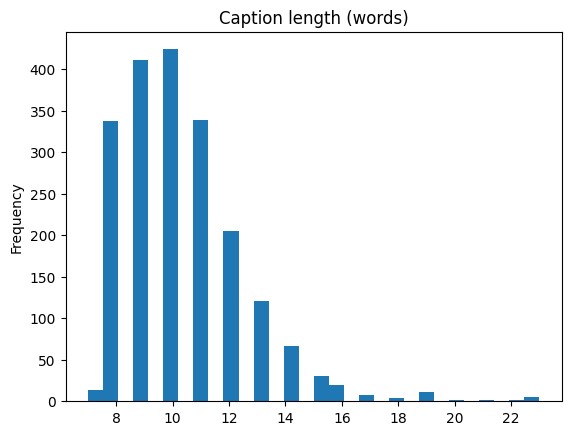

In [14]:
manifest["n_words"] = manifest["caption"].str.split().str.len()

print(f"Image count:              {len(manifest)}")
print(f"Avg caption length:       {manifest['n_words'].mean():.1f} words "
      f"(median {manifest['n_words'].median():.0f}, min {manifest['n_words'].min()}, max {manifest['n_words'].max()})")
print(f"Dropped during selection: {dict(dropped)}")
print(f"Caption rule:             {CAPTION_RULE}")

manifest["n_words"].plot.hist(bins=30, title="Caption length (words)");

8. Example pairs figure

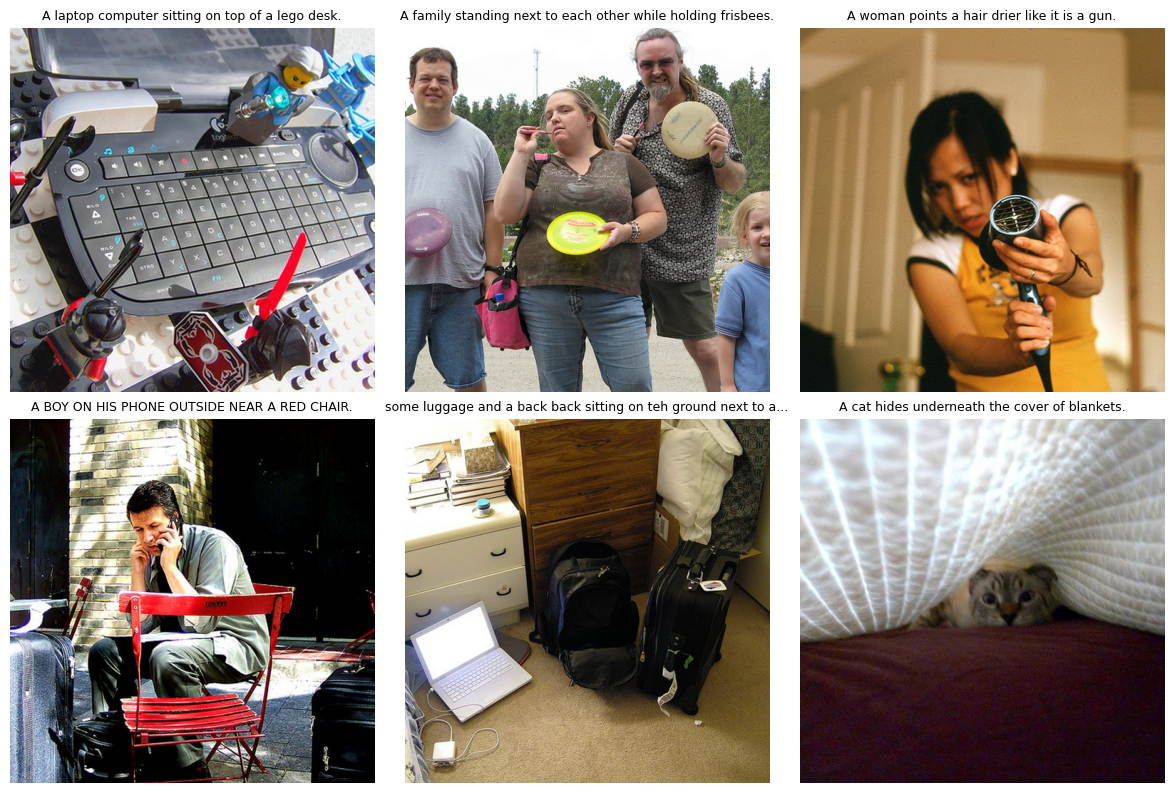

In [15]:
import matplotlib.pyplot as plt

samples = manifest.sample(6, random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (_, row) in zip(axes.ravel(), samples.iterrows()):
    ax.imshow(Image.open(ROOT / row["file_path"]))
    ax.set_title(row["caption"][:60] + ("..." if len(row["caption"]) > 60 else ""), fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(ROOT / "example_pairs.png", dpi=150)
plt.show()